# ANN for numeric video features

A compact multilayer perceptron predicts `final_label` (0/1) from views, likes, duration in seconds, and the like ratio (likes / views). The notebook uses the existing stratified train, validation, and test splits. It transforms skewed counts, fits scaling on training data only, applies L2 regularization, and uses validation loss with patience-based early stopping. The test split is evaluated once after model selection.

## 1. Imports and reproducibility

In [1]:
from copy import deepcopy
from pathlib import Path
import random
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)


## 2. Load the prepared splits

Run from the repository root or from `models/`. No new split is created, so the held-out test set remains untouched during training and tuning.

In [2]:
ROOT = Path.cwd()
if not (ROOT / 'data' / 'processed').exists() and (ROOT.parent / 'data' / 'processed').exists():
    ROOT = ROOT.parent

DATA_DIR = ROOT / 'data' / 'processed'
train_df = pd.read_csv(DATA_DIR / 'train.csv')
validation_df = pd.read_csv(DATA_DIR / 'validation.csv')
test_df = pd.read_csv(DATA_DIR / 'test.csv')

TARGET = 'final_label'
REQUIRED_COLUMNS = ['views', 'likes', 'duration', TARGET]
for split_name, split_df in [('train', train_df), ('validation', validation_df), ('test', test_df)]:
    missing = [column for column in REQUIRED_COLUMNS if column not in split_df.columns]
    if missing:
        raise KeyError(f'{split_name} split is missing columns: {missing}')
    print(f'{split_name}: {len(split_df):,} rows')

train_df[TARGET].value_counts(normalize=True).sort_index().rename('train_fraction')


train: 2,957 rows
validation: 634 rows
test: 634 rows


final_label
0    0.788637
1    0.211363
Name: train_fraction, dtype: float64

## 3. Prepare numeric features

`duration` is parsed as seconds (accepting values such as `1954s` as well as numeric values). `like_ratio` is computed safely and is zero when views are zero. `log1p` reduces the extreme skew in views and likes. Rows with missing or invalid values in required fields are excluded consistently per split.

In [3]:
FEATURES = ['views', 'likes', 'duration_seconds', 'like_ratio']

def duration_to_seconds(value):
    if pd.isna(value):
        return np.nan
    if isinstance(value, (int, float, np.number)):
        return float(value)
    text = str(value).strip().lower()
    match = re.fullmatch(r'(\d+(?:\.\d+)?)\s*s?', text)
    return float(match.group(1)) if match else np.nan

def prepare_split(frame):
    data = frame.copy()
    data['views'] = pd.to_numeric(data['views'], errors='coerce')
    data['likes'] = pd.to_numeric(data['likes'], errors='coerce')
    data['duration_seconds'] = data['duration'].map(duration_to_seconds)
    data[TARGET] = pd.to_numeric(data[TARGET], errors='coerce')
    data['like_ratio'] = data['likes'].div(data['views'].replace(0, np.nan)).fillna(0.0)
    data = data.replace([np.inf, -np.inf], np.nan)
    data = data.dropna(subset=['views', 'likes', 'duration_seconds', TARGET]).copy()
    if (data[['views', 'likes', 'duration_seconds']] < 0).any().any():
        raise ValueError('Views, likes, and duration must be non-negative for log1p.')
    data['views'] = np.log1p(data['views'])
    data['likes'] = np.log1p(data['likes'])
    data['duration_seconds'] = np.log1p(data['duration_seconds'])
    data[TARGET] = data[TARGET].astype(int)
    if not set(data[TARGET].unique()).issubset({0, 1}):
        raise ValueError(f'{TARGET} must contain only binary labels 0 and 1.')
    return data

train = prepare_split(train_df)
validation = prepare_split(validation_df)
test = prepare_split(test_df)

X_train_raw, y_train = train[FEATURES], train[TARGET].to_numpy()
X_val_raw, y_val = validation[FEATURES], validation[TARGET].to_numpy()
X_test_raw, y_test = test[FEATURES], test[TARGET].to_numpy()

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_val = scaler.transform(X_val_raw)
X_test = scaler.transform(X_test_raw)

print('Rows after numeric validation:', {'train': len(train), 'validation': len(validation), 'test': len(test)})
print('Feature order:', FEATURES)


Rows after numeric validation: {'train': 2957, 'validation': 634, 'test': 634}
Feature order: ['views', 'likes', 'duration_seconds', 'like_ratio']


## 4. Train with validation-based early stopping

This deliberately small network has one 16-unit hidden layer. L2 weight decay (`alpha`) discourages overly complex fits. After each epoch the model is scored on the validation set; the best weights are saved and training stops when validation log loss has not improved for 20 epochs. The test data is not used here.

In [4]:
model = MLPClassifier(
    hidden_layer_sizes=(16,),
    activation='relu',
    solver='adam',
    alpha=0.01,
    batch_size=64,
    learning_rate_init=0.001,
    max_iter=1,
    warm_start=True,
    shuffle=True,
    random_state=RANDOM_STATE,
)

MAX_EPOCHS = 300
PATIENCE = 20
MIN_DELTA = 1e-4
classes = np.array([0, 1])
history = {'train_loss': [], 'validation_loss': []}
best_validation_loss = np.inf
best_model = None
best_epoch = 0
epochs_without_improvement = 0

for epoch in range(1, MAX_EPOCHS + 1):
    if epoch == 1:
        model.partial_fit(X_train, y_train, classes=classes)
    else:
        model.partial_fit(X_train, y_train)

    train_probabilities = model.predict_proba(X_train)
    validation_probabilities = model.predict_proba(X_val)
    train_loss = log_loss(y_train, train_probabilities, labels=classes)
    validation_loss = log_loss(y_val, validation_probabilities, labels=classes)
    history['train_loss'].append(train_loss)
    history['validation_loss'].append(validation_loss)

    if validation_loss < best_validation_loss - MIN_DELTA:
        best_validation_loss = validation_loss
        best_model = deepcopy(model)
        best_epoch = epoch
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 10 == 0:
        print(f'Epoch {epoch:03d} | train log loss {train_loss:.4f} | validation log loss {validation_loss:.4f}')

    if epochs_without_improvement >= PATIENCE:
        print(f'Early stopping at epoch {epoch}; best validation epoch was {best_epoch}.')
        break

model = best_model
print(f'Using epoch {best_epoch} (best validation log loss: {best_validation_loss:.4f})')


Epoch 001 | train log loss 0.5261 | validation log loss 0.5234
Epoch 010 | train log loss 0.3389 | validation log loss 0.3393
Epoch 020 | train log loss 0.3180 | validation log loss 0.3171
Epoch 030 | train log loss 0.3115 | validation log loss 0.3113
Epoch 040 | train log loss 0.3072 | validation log loss 0.3070
Epoch 050 | train log loss 0.3038 | validation log loss 0.3033
Epoch 060 | train log loss 0.2999 | validation log loss 0.2986
Epoch 070 | train log loss 0.2961 | validation log loss 0.2943
Epoch 080 | train log loss 0.2919 | validation log loss 0.2907
Epoch 090 | train log loss 0.2866 | validation log loss 0.2864
Epoch 100 | train log loss 0.2822 | validation log loss 0.2824
Epoch 110 | train log loss 0.2786 | validation log loss 0.2792
Epoch 120 | train log loss 0.2757 | validation log loss 0.2766
Epoch 130 | train log loss 0.2734 | validation log loss 0.2748
Epoch 140 | train log loss 0.2716 | validation log loss 0.2732
Epoch 150 | train log loss 0.2702 | validation log loss

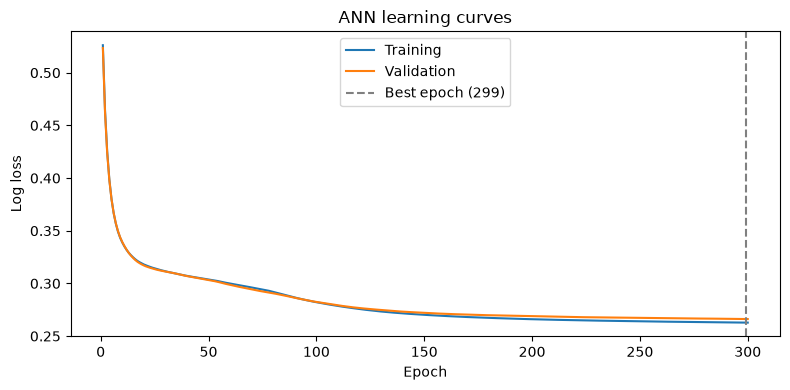

In [5]:
epochs = np.arange(1, len(history['train_loss']) + 1)
plt.figure(figsize=(8, 4))
plt.plot(epochs, history['train_loss'], label='Training')
plt.plot(epochs, history['validation_loss'], label='Validation')
plt.axvline(best_epoch, color='gray', linestyle='--', label=f'Best epoch ({best_epoch})')
plt.xlabel('Epoch')
plt.ylabel('Log loss')
plt.title('ANN learning curves')
plt.legend()
plt.tight_layout()
plt.show()


## 5. Check generalization on validation data

The validation report is for model selection and a generalization check. A large gap between training and validation scores can indicate overfitting.

In [6]:
def evaluate_split(name, fitted_model, features, labels):
    probabilities = fitted_model.predict_proba(features)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)
    metrics = {
        'accuracy': accuracy_score(labels, predictions),
        'precision': precision_score(labels, predictions, zero_division=0),
        'recall': recall_score(labels, predictions, zero_division=0),
        'f1': f1_score(labels, predictions, zero_division=0),
        'roc_auc': roc_auc_score(labels, probabilities) if len(np.unique(labels)) == 2 else np.nan,
        'log_loss': log_loss(labels, fitted_model.predict_proba(features), labels=[0, 1]),
    }
    print(f'--- {name} ---')
    print(pd.Series(metrics).round(4))
    print('Confusion matrix [ [TN, FP], [FN, TP] ]:')
    print(confusion_matrix(labels, predictions, labels=[0, 1]))
    print(classification_report(labels, predictions, labels=[0, 1], zero_division=0))
    return metrics

train_metrics = evaluate_split('Train', model, X_train, y_train)
validation_metrics = evaluate_split('Validation', model, X_val, y_val)
print('Train minus validation F1 gap:', round(train_metrics['f1'] - validation_metrics['f1'], 4))


--- Train ---
accuracy     0.8799
precision    0.6985
recall       0.7600
f1           0.7280
roc_auc      0.9309
log_loss     0.2628
dtype: float64
Confusion matrix [ [TN, FP], [FN, TP] ]:
[[2127  205]
 [ 150  475]]
              precision    recall  f1-score   support

           0       0.93      0.91      0.92      2332
           1       0.70      0.76      0.73       625

    accuracy                           0.88      2957
   macro avg       0.82      0.84      0.83      2957
weighted avg       0.88      0.88      0.88      2957

--- Validation ---
accuracy     0.8817
precision    0.6928
recall       0.7910
f1           0.7387
roc_auc      0.9266
log_loss     0.2662
dtype: float64
Confusion matrix [ [TN, FP], [FN, TP] ]:
[[453  47]
 [ 28 106]]
              precision    recall  f1-score   support

           0       0.94      0.91      0.92       500
           1       0.69      0.79      0.74       134

    accuracy                           0.88       634
   macro avg       0

## 6. Final held-out test evaluation

Run this section after training and validation checks. These are the final generalization metrics on the untouched test split.

In [7]:
test_metrics = evaluate_split('Test (held out)', model, X_test, y_test)


--- Test (held out) ---
accuracy     0.8896
precision    0.7388
recall       0.7388
f1           0.7388
roc_auc      0.9178
log_loss     0.2746
dtype: float64
Confusion matrix [ [TN, FP], [FN, TP] ]:
[[465  35]
 [ 35  99]]
              precision    recall  f1-score   support

           0       0.93      0.93      0.93       500
           1       0.74      0.74      0.74       134

    accuracy                           0.89       634
   macro avg       0.83      0.83      0.83       634
weighted avg       0.89      0.89      0.89       634



## Notes

This is a binary classifier: it predicts `final_label` from the four numeric features. The like ratio uses the available `likes` and `views` counts. If a different numeric target is intended, change `TARGET` and the output/loss setup accordingly; this notebook currently follows the repository's clickbait label task.